In [1]:
import pandas as pd
from datasets import InferenceDataset

In [2]:
from modules import SalsaNet
import torch

# Load the model
model_path = "SALSA_20250318133917/model_trained_model.pt"
model = SalsaNet(dim_emb=512, dim_salsa=32, n_heads=8, L_enc=8, L_dec=8, dim_ff=2048)
model.load_state_dict(torch.load(model_path, map_location=torch.device('cpu')))
model.eval()

SalsaNet(
  (embedding): Embedding(39, 512)
  (pos_enc): PositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (enc): TransformerEncoder(
    (layers): ModuleList(
      (0-7): 8 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=512, bias=True)
        (norm1): LayerNorm((512,), eps=0.6, elementwise_affine=True)
        (norm2): LayerNorm((512,), eps=0.6, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (pma): PMA(
    (mab): MAB(
      (fc_q): Linear(in_features=512, out_features=512, bias=True)
      (fc_k): Linear(in_features=512, out_features=512, bias=True)
      (fc_v

In [4]:
df = pd.read_csv("/work/users/s/h/shuhang/5feb2025/anchor_mutant_pairs_5feb2025.csv.part0059")

In [6]:
# Create lists to store the data
all_smiles = []
family_ids = []

# Group by 'anchor' to dynamically determine family IDs
grouped = df.groupby('anchor', sort=False)
for i, (anchor, group) in enumerate(grouped):
    # Create a unique family ID for each anchor
    family_id = f"{i}"
    # Append the family ID to the list
    family_ids.extend([family_id] * (len(group) + 1))
    
    # Append the SMILES strings and is_anchor values to their respective lists
    all_smiles.append(anchor)
    all_smiles.extend(group['mutant'].tolist())

In [7]:
grouped_df = pd.DataFrame({
    'SMILES': all_smiles,
    'fam_id': family_ids
})

In [9]:
# Load the dataset
test_dataset = InferenceDataset(grouped_df)

In [10]:
from torch.utils.data import DataLoader

# Create a DataLoader for the inference dataset
inference_loader = DataLoader(test_dataset, batch_size=11, shuffle=False)

# Run inference
model.eval()
predictions = []
with torch.no_grad():
    for i, data in enumerate(inference_loader):
        if i == 8:
            break

        output = model(**data)[0]
        print(output)
        predictions.append(output)

tensor([[-1.4362e-01, -1.4554e-01, -1.9544e-03, -1.3044e-01, -1.4732e-01,
         -1.8014e-01, -3.5664e-02, -1.4934e-01, -5.9712e-02,  8.3567e-02,
         -1.4013e-01, -2.2671e-01,  2.0632e-01, -4.4962e-01, -2.3925e-01,
         -6.5999e-02,  5.1953e-02,  1.8048e-01, -1.2855e-01,  1.9847e-01,
         -2.0800e-01, -2.6646e-01, -7.1181e-02, -3.0762e-01,  8.4161e-02,
          4.7084e-02, -1.8181e-01,  9.5093e-02,  9.0241e-02,  2.3841e-01,
         -1.6302e-01, -1.6560e-01],
        [-1.3367e-01, -1.3168e-01,  2.1880e-03, -1.8668e-01, -1.2233e-01,
         -1.8099e-01, -2.8078e-02, -1.5678e-01, -5.9775e-02,  8.5264e-02,
         -1.4999e-01, -2.3999e-01,  2.2518e-01, -4.2252e-01, -2.5355e-01,
         -8.9084e-02,  6.6851e-02,  1.7882e-01, -1.1552e-01,  2.0301e-01,
         -1.9182e-01, -2.6696e-01, -5.9945e-02, -2.9815e-01,  1.0140e-01,
          2.7157e-02, -1.9947e-01,  8.6388e-02,  9.5338e-02,  2.2434e-01,
         -1.5503e-01, -1.7659e-01],
        [-1.5526e-01, -1.5263e-01, -7.13

In [14]:
len(predictions) # B, N, L

8

In [15]:
import torch

are_equal = torch.equal(predictions[0][0], predictions[1][0])
print("Are predictions[0][0] and predictions[0][1] equal?", are_equal)

Are predictions[0][0] and predictions[0][1] equal? False


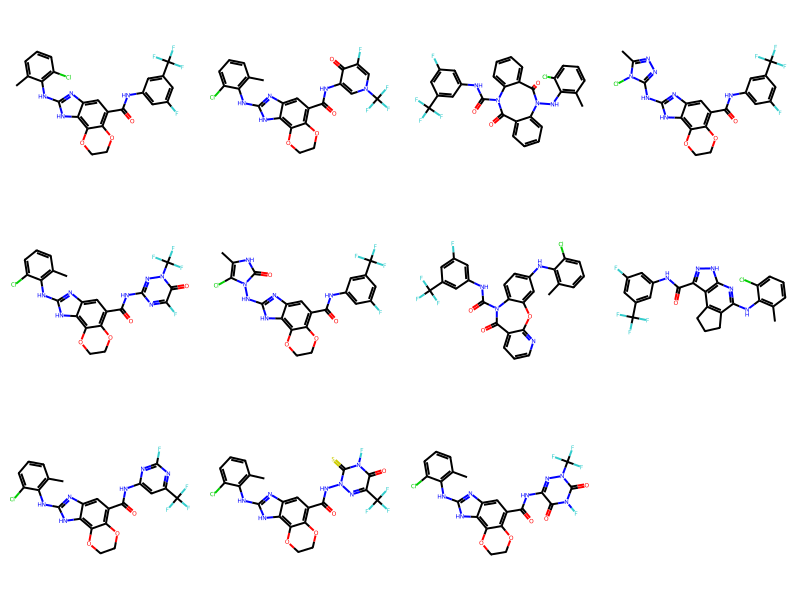

In [16]:
from rdkit import Chem
from rdkit.Chem import Draw

# Convert SMILES strings to RDKit molecule objects
mols = [Chem.MolFromSmiles(smiles) for smiles in grouped_df['SMILES'].head(11)]

# Draw the molecules in a grid image
img = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(200, 200))
img

In [19]:
torch.nn.functional.cosine_similarity(predictions[0][0], predictions[4][0], dim=0)

tensor(0.3371)

In [20]:
torch.nn.functional.cosine_similarity(predictions[0][0], predictions[0][1], dim=0)

tensor(0.9957)

In [22]:
import datamol as dm

# Calculate the pairwise Tanimoto similarity
similarity_matrix = dm.similarity.pdist(mols)

# Print the similarity matrix
print(similarity_matrix)

[[0.         0.35964912 0.6641791  0.33944954 0.35652174 0.38938053
  0.62589928 0.55555556 0.33333333 0.42622951 0.37068966]
 [0.35964912 0.         0.78666667 0.58461538 0.34482759 0.60902256
  0.74025974 0.72413793 0.36521739 0.41463415 0.34482759]
 [0.6641791  0.78666667 0.         0.77777778 0.77333333 0.74468085
  0.52380952 0.64885496 0.79194631 0.78571429 0.78947368]
 [0.33944954 0.58461538 0.77777778 0.         0.58015267 0.37272727
  0.75496689 0.72142857 0.56692913 0.63043478 0.59090909]
 [0.35652174 0.34482759 0.77333333 0.58015267 0.         0.60447761
  0.74358974 0.72789116 0.37606838 0.39837398 0.29824561]
 [0.38938053 0.60902256 0.74468085 0.37272727 0.60447761 0.
  0.74       0.71428571 0.60305344 0.65248227 0.60447761]
 [0.62589928 0.74025974 0.52380952 0.75496689 0.74358974 0.74
  0.         0.63043478 0.75324675 0.75625    0.75159236]
 [0.55555556 0.72413793 0.64885496 0.72142857 0.72789116 0.71428571
  0.63043478 0.         0.72027972 0.73333333 0.71917808]
 [0.33

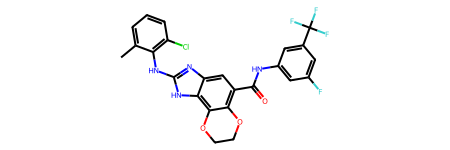

In [24]:
mols[0]

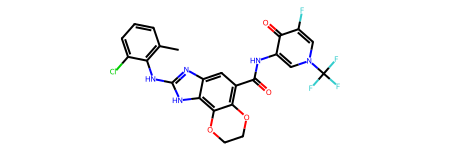

In [25]:
mols[1]

In [26]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Extract all vectors from predictions
vectors = [pred.numpy().reshape(1, -1) for pred in predictions[0][0]]

# Calculate pairwise cosine similarity
cosine_sim_matrix = cosine_similarity(np.vstack(vectors))

# Print the similarity matrix
print(cosine_sim_matrix)

[[ 1.  1.  1. ... -1.  1.  1.]
 [ 1.  1.  1. ... -1.  1.  1.]
 [ 1.  1.  1. ... -1.  1.  1.]
 ...
 [-1. -1. -1. ...  1. -1. -1.]
 [ 1.  1.  1. ... -1.  1.  1.]
 [ 1.  1.  1. ... -1.  1.  1.]]


In [27]:
import pickle

# Unpickle the file
with open('SALSA_20250318133917/losses.pkl', 'rb') as f:
    losses = pickle.load(f)

In [28]:
print(len(losses))

382854


In [30]:
382854/3

127618.0

Number of epochs: 3


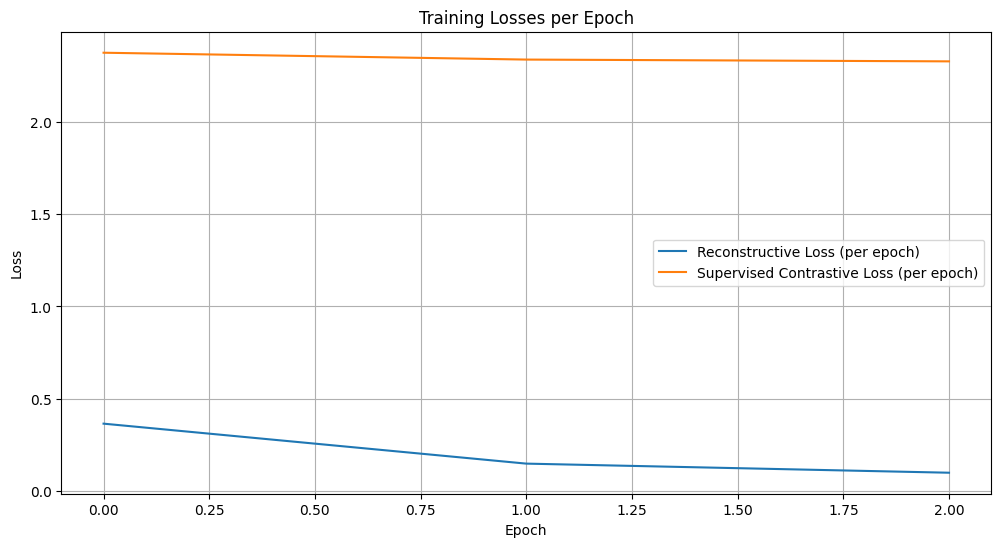

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# First calculate epoch averages
batches_per_epoch = 127618
num_epochs = len(losses) // batches_per_epoch

print(f"Number of epochs: {num_epochs}")

# Initialize storage
epoch_recon = []
epoch_contrast = []

for epoch in range(num_epochs):
    # Get batch losses for this epoch
    start_idx = epoch * batches_per_epoch
    end_idx = (epoch + 1) * batches_per_epoch
    epoch_losses = losses[start_idx:end_idx]
    
    # Calculate averages
    epoch_recon.append(np.mean([loss[0] for loss in epoch_losses]))
    epoch_contrast.append(np.mean([loss[1] for loss in epoch_losses]))

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(epoch_recon, label='Reconstructive Loss (per epoch)')
plt.plot(epoch_contrast, label='Supervised Contrastive Loss (per epoch)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Losses per Epoch')
plt.legend()
plt.grid(True)
plt.show()
